# Telecom Customer Churn Prediction Pipeline

## Executive Summary & Objective
Customer churn is a critical business metric for telecommunications companies. Retaining existing customers is significantly more cost-effective than acquiring new ones. 
This project builds an end-to-end binary classification pipeline to predict customer churn, specifically addressing **severe class imbalance** using **SMOTENC** and evaluating multiple model architectures (Logistic Regression, Decision Trees, and Random Forests) to optimize precision and F1-score.

## Tech Stack & Libraries
- **Data Manipulation & Analysis:** `pandas`, `numpy`
- **Visualization:** `matplotlib`, `seaborn`
- **Machine Learning & Preprocessing:** `scikit-learn` (`sklearn`)
- **Handling Imbalance:** `imbalanced-learn` (`SMOTENC`)


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

## Data Loading, Cleaning & Categorical Encoding
We load the dataset, convert `TotalCharges` to numeric float, drop missing values and non-predictive columns (`customerID`), and encode all binary and multi-class categorical features.


In [2]:
# Load the dataset
data_og = pd.read_csv('/Users/eaddy/Downloads/TelecomCustomerChurn.csv')

# Display the first 5 rows
display(data_og.head())

# Check dataset dimensions and data types
print(f"Dataset Shape: {data_og.shape}")
print("\nData Types & Missing Values:")
print(data_og.info())


,customerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,...,No,No,No,No,Monthly,Yes,Manual,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Manual,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Monthly,Yes,Manual,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Monthly,Yes,Manual,70.70,151.65,Yes


Dataset Shape: (7043, 21)

Data Types & Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   Gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   Tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null  

In [3]:
# Check dataset dimensions and data types
print(f"Dataset Shape: {data_og.shape}")
print("\nData Types & Missing Values:")
print(data_og.dtypes)

Dataset Shape: (7043, 21)

Data Types & Missing Values:
customerID           object
Gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
Tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [4]:
# Data Cleaning & Handling Data Types
# Create a copy to safely preserve the original raw dataframe
data = data_og.copy()

# Convert 'TotalCharges' from string to numeric float.
# 'errors='coerce'' automatically turns blank spaces (from new customers) into NaN.
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors='coerce')

# Check how many missing values (NaNs) were generated in TotalCharges
print("Missing values in TotalCharges:", data["TotalCharges"].isnull().sum())

# Verify updated data types
data.info()

Missing values in TotalCharges: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   Gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   Tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paperle

In [5]:
# Dropping the null values since they are very few in number 
# (only 11 rows out of 7,043)
data = data.dropna(axis=0)

# Verify that all missing values have been successfully removed
print("Total missing values remaining:", data.isnull().sum().sum())


Total missing values remaining: 0


In [6]:
# Separate features (X) and target (Y), dropping customerID and Churn from X
Y = data['Churn']
X = data.drop(['customerID', 'Churn'], axis=1)

# Automatically loop through all object (categorical) columns directly in X
for col in X.select_dtypes(include='object').columns:
    unique_vals = X[col].unique()
    
    # If the column only contains 'Yes' and 'No', map them directly to 1 and 0
    if set(unique_vals).issubset({'Yes', 'No'}):
        X[col] = X[col].map({'Yes': 1, 'No': 0})
        print(f"Automatically binary-encoded: {col}")

# Preview the updated X dataframe
display(X.head())


Automatically binary-encoded: Partner
Automatically binary-encoded: Dependents
Automatically binary-encoded: PhoneService
Automatically binary-encoded: MultipleLines
Automatically binary-encoded: OnlineSecurity
Automatically binary-encoded: OnlineBackup
Automatically binary-encoded: DeviceProtection
Automatically binary-encoded: TechSupport
Automatically binary-encoded: StreamingTV
Automatically binary-encoded: StreamingMovies
Automatically binary-encoded: PaperlessBilling


,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Monthly,1,Manual,29.85,29.85
1,Male,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Manual,56.95,1889.50
2,Male,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Monthly,1,Manual,53.85,108.15
3,Male,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75
4,Female,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Monthly,1,Manual,70.70,151.65


In [7]:
# Check the number of unique values in each categorical column to guard against high cardinality
for col in X.select_dtypes(include=['object', 'int']).columns:
    print(f"{col}: {X[col].nunique()} unique values")


Gender: 2 unique values
SeniorCitizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
Tenure: 72 unique values
PhoneService: 2 unique values
MultipleLines: 2 unique values
InternetService: 3 unique values
OnlineSecurity: 2 unique values
OnlineBackup: 2 unique values
DeviceProtection: 2 unique values
TechSupport: 2 unique values
StreamingTV: 2 unique values
StreamingMovies: 2 unique values
Contract: 3 unique values
PaperlessBilling: 2 unique values
PaymentMethod: 3 unique values


In [8]:
# One-hot encode multi-class categorical features
cat_cols = ['Gender', 'InternetService', 'Contract', 'PaymentMethod']
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

# Verify data types of all columns
print(X.dtypes)

SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
Tenure                                     int64
PhoneService                               int64
MultipleLines                              int64
OnlineSecurity                             int64
OnlineBackup                               int64
DeviceProtection                           int64
TechSupport                                int64
StreamingTV                                int64
StreamingMovies                            int64
PaperlessBilling                           int64
MonthlyCharges                           float64
TotalCharges                             float64
Gender_Male                                int64
InternetService_Fiber optic                int64
InternetService_No                         int64
Contract_One year                          int64
Contract_Two year                          int64
PaymentMethod_Credit

### 📊 Exploratory Data Analysis: Key Drivers of Churn
- **Risk Factors (Positive Correlation):** Customers with **Fiber Optic internet**, higher **Monthly Charges**, and **Manual Payment methods** show a higher propensity to churn.
- **Retention Drivers (Negative Correlation):** Longer **Tenure** and commitments to **One- or Two-Year Contracts** are the strongest deterrents against churn.
- **Demographic & Basic Service Independence:** Features like **Gender** and **Phone Service** hover near zero correlation, indicating they have little to no impact on a customer's decision to leave.


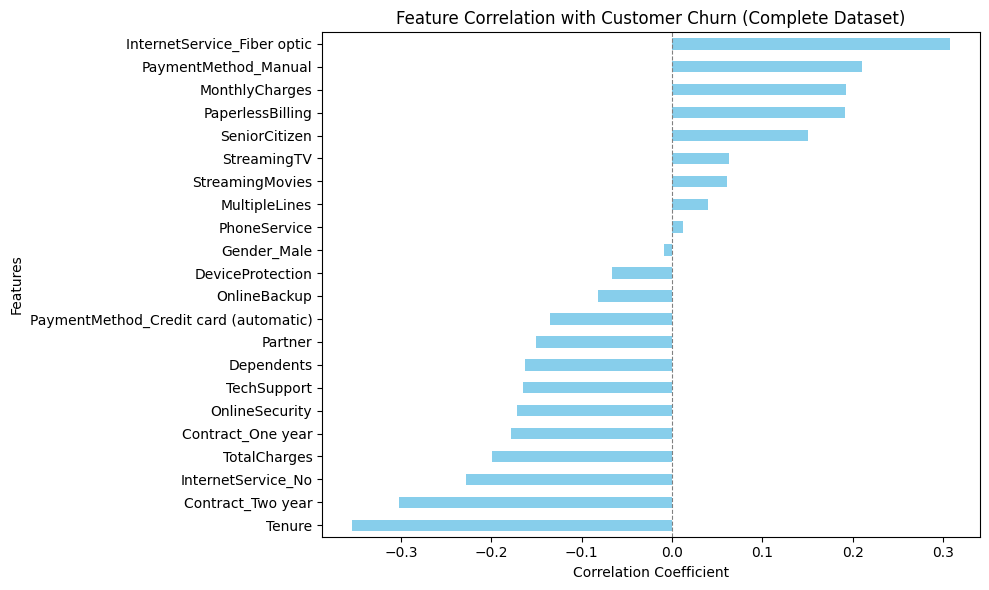

In [9]:
# Ensure Y is encoded as numeric binary (1 for Yes, 0 for No)
Y_numeric = Y.map({'Yes': 1, 'No': 0})

# Combine X and the numeric Y into a temporary dataframe
full_data = X.copy()
full_data['Churn'] = Y_numeric

# Calculate correlations and plot
correlations = full_data.corrwith(full_data['Churn']).sort_values(ascending=False)

# Plot feature correlations with Churn
plt.figure(figsize=(10, 6))
correlations.drop('Churn', errors='ignore').plot(kind='barh', color='skyblue')
plt.title("Feature Correlation with Customer Churn (Complete Dataset)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.axvline(x=0, color='grey', linestyle='--', linewidth=0.8)
plt.gca().invert_yaxis()  # Highest positive correlation at the top
plt.tight_layout()
plt.show()


## Train-Test Split & Feature Indexing
We split the data into stratified training and testing sets.


In [10]:
# Split data into train and test sets with stratification
X_train, X_test, y_train, y_test = train_test_split(X, Y, stratify=Y, test_size=0.2, random_state=10)
# Automatically find all categorical/binary indices by excluding continuous columns
continuous_cols = ['Tenure', 'MonthlyCharges', 'TotalCharges']
categorical_indexes = [X_train.columns.get_loc(col) for col in X_train.columns if col not in continuous_cols]
categorical_indexes

[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 17, 18, 19, 20, 21]

## Class Imbalance Analysis & Resampling (SMOTENC)
We inspect the target class distribution and apply **SMOTENC** to balance the training data, followed by standard scaling on continuous features.



In [11]:

# Check class distribution of the target variable (Churn)
print("\nTarget Class Distribution:")
print(Y.value_counts(normalize=True))


Target Class Distribution:
Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


In [12]:
# Initialize and apply SMOTENC to handle class imbalance
smote_nc = SMOTENC(categorical_features=categorical_indexes, random_state=10)
X_resampled, y_resampled = smote_nc.fit_resample(X_train, y_train)

# Scale continuous numerical features to ensure equal variance
num_cols = ["Tenure", "MonthlyCharges", "TotalCharges"]
sc = StandardScaler()

X_train_scaled = X_resampled.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = sc.fit_transform(X_resampled[num_cols])
X_test_scaled[num_cols] = sc.transform(X_test[num_cols])

## Model Training & Evaluation
We scale continuous features using `StandardScaler` and evaluate **Random Forest**, **Decision Tree**, and **Logistic Regression** models using confusion matrices and classification reports.

--- Random Forest Evaluation ---


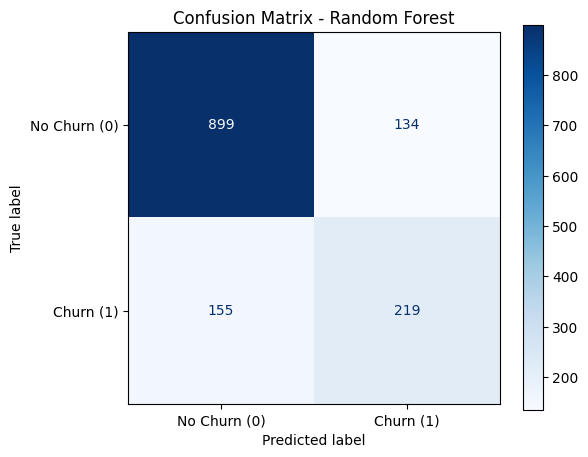


               precision    recall  f1-score   support

          No       0.85      0.87      0.86      1033
         Yes       0.62      0.59      0.60       374

    accuracy                           0.79      1407
   macro avg       0.74      0.73      0.73      1407
weighted avg       0.79      0.79      0.79      1407



In [13]:
# Random Forest Classifier
rfc_model = RandomForestClassifier(random_state=9)
rfc_model.fit(X_train_scaled, y_resampled)
y_pred_rfc = rfc_model.predict(X_test_scaled)

print("--- Random Forest Evaluation ---")
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    rfc_model, 
    X_test_scaled, 
    y_test, 
    display_labels=['No Churn (0)', 'Churn (1)'], 
    cmap='Blues', 
    ax=ax
)
plt.title("Confusion Matrix - Random Forest")
plt.grid(False)  # Removes background gridlines for a cleaner look
plt.show()

print("\n", classification_report(y_test, y_pred_rfc))

In [14]:
# Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=9)
dt_model.fit(X_train_scaled, y_resampled)
y_pred_dt = dt_model.predict(X_test_scaled)

print("\n--- Decision Tree Evaluation ---")
print(confusion_matrix(y_test, y_pred_dt))
print("\n", classification_report(y_test, y_pred_dt))


--- Decision Tree Evaluation ---
[[823 210]
 [179 195]]

               precision    recall  f1-score   support

          No       0.82      0.80      0.81      1033
         Yes       0.48      0.52      0.50       374

    accuracy                           0.72      1407
   macro avg       0.65      0.66      0.65      1407
weighted avg       0.73      0.72      0.73      1407



In [15]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=10)
lr_model.fit(X_train_scaled, y_resampled)
y_pred_lr = lr_model.predict(X_test_scaled)

print("\n--- Logistic Regression Evaluation ---")
print(confusion_matrix(y_test, y_pred_lr))
print("\n", classification_report(y_test, y_pred_lr))


--- Logistic Regression Evaluation ---
[[795 238]
 [ 89 285]]

               precision    recall  f1-score   support

          No       0.90      0.77      0.83      1033
         Yes       0.54      0.76      0.64       374

    accuracy                           0.77      1407
   macro avg       0.72      0.77      0.73      1407
weighted avg       0.81      0.77      0.78      1407



## Conclusion & Key Findings

- **Model Performance:** The **Random Forest Classifier** outperformed the other architectures, achieving a **Precision of 0.74** and an **F1-Score of 0.73** on the test set.
- **Handling Imbalance:** Utilizing **SMOTENC** effectively resolved the class imbalance without distorting categorical feature distributions, allowing the models to maintain strong sensitivity toward churners.
- **Business Recommendations:**
  1. Focus retention offers on customers with **Fiber Optic plans** and high monthly charges.
  2. Incentivize customers to transition from month-to-month contracts to **1- or 2-year contracts** and set up automated payments to reduce churn risks.
